In [ ]:
import pandas as pd
import glob
import os

print("Librerias listas para trabajar")
# 1. Identificar todos los archivos CSV en la carpeta
archivos_csv = sorted(glob.glob("*.csv"))
print(f"Total de archivos detectados: {len(archivos_csv)}")

# 2. Leerlos y concatenarlos todos en un solo DataFrame
df = pd.concat((pd.read_csv(archivo) for archivo in archivos_csv), ignore_index=True)

# 3. Mostrar cuántas filas y columnas se cargaron
print(f"Total de filas consolidadas: {df.shape[0]:,}")
print(f"Total de columnas: {df.shape[1]}")
df.head(3)

Librerias listas para trabajar
Total de archivos detectados: 12
Total de filas consolidadas: 4,987,239
Total de columnas: 13


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,7569BC890583FCD7,classic_bike,2025-01-21 17:23:54.538,2025-01-21 17:37:52.015,Wacker Dr & Washington St,KA1503000072,McClurg Ct & Ohio St,TA1306000029,41.883143,-87.637242,41.892592,-87.617289,member
1,013609308856B7FC,electric_bike,2025-01-11 15:44:06.795,2025-01-11 15:49:11.139,Halsted St & Wrightwood Ave,TA1309000061,Racine Ave & Belmont Ave,TA1308000019,41.929147,-87.649153,41.939743,-87.658865,member
2,EACACD3CE0607C0D,classic_bike,2025-01-02 15:16:27.730,2025-01-02 15:28:03.230,Southport Ave & Waveland Ave,13235,Broadway & Cornelia Ave,13278,41.948226,-87.664071,41.945529,-87.646439,member


In [ ]:
# 1. Convertir las columnas de fecha a formato datetime
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])

# 2. Calcular 'ride_length' en minutos (duración real del viaje)
df['ride_length'] = (df['ended_at'] - df['started_at']).dt.total_seconds() / 60

# 3. Extraer el día de la semana y su nombre legible
# day_of_week: 1 = Domingo, 7 = Sábado (estándar solicitado por la guía)
df['day_of_week'] = (df['started_at'].dt.weekday + 1) % 7 + 1
df['day_name'] = df['started_at'].dt.day_name()

# 4. Limpieza: Filtrar registros inconsistentes (viajes negativos o menores a 1 minuto por errores de estación)
df_clean = df[df['ride_length'] >= 1].copy()

print(f"Filas originales: {len(df):,}")
print(f"Filas limpias y válidas: {len(df_clean):,}")
print(f"Viajes descartados (menores a 1 min o negativos): {len(df) - len(df_clean):,}")

# Ver un resumen rápido de las columnas creadas
df_clean[['started_at', 'ended_at', 'ride_length', 'day_of_week', 'day_name', 'member_casual']].head(3)

Filas originales: 4,987,239
Filas limpias y válidas: 4,858,017
Viajes descartados (menores a 1 min o negativos): 129,222


,started_at,ended_at,ride_length,day_of_week,day_name,member_casual
0,2025-01-21 17:23:54.538,2025-01-21 17:37:52.015,13.957950,3,Tuesday,member
1,2025-01-11 15:44:06.795,2025-01-11 15:49:11.139,5.072400,7,Saturday,member
2,2025-01-02 15:16:27.730,2025-01-02 15:28:03.230,11.591667,5,Thursday,member


In [ ]:
# 1. Comparación general: Promedio, Mediana y Máximo de duración por tipo de usuario
metricas_usuario = df_clean.groupby('member_casual')['ride_length'].agg(
    total_viajes='count',
    promedio_min='mean',
    mediana_min='median',
    maximo_min='max'
).round(2)

print("--- Comparativa General de Usuarios ---")
display(metricas_usuario)

# 2. Comportamiento por día de la semana (Volumen y Duración promedio)
resumen_semanal = df_clean.groupby(['day_name', 'member_casual'])['ride_length'].agg(
    total_viajes='count',
    promedio_min='mean'
).round(2).unstack()

# Ordenar los días cronológicamente
orden_dias = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
resumen_semanal = resumen_semanal.reindex(orden_dias)

print("\n--- Patrón por Día de la Semana ---")
display(resumen_semanal)

--- Comparativa General de Usuarios ---


,total_viajes,promedio_min,mediana_min,maximo_min
member_casual,,,,
casual,1682658,23.09,11.73,1559.92
member,3175358,12.50,8.66,1499.97



--- Patrón por Día de la Semana ---


total_viajes         promedio_min       
member_casual       casual  member       casual member
day_name                                              
Sunday              272906  333231        27.03  13.86
Monday              189693  441435        22.84  12.05
Tuesday             191198  505135        20.20  12.10
Wednesday           191981  501766        19.08  11.96
Thursday            217337  518358        20.09  12.06
Friday              273858  476395        23.16  12.47
Saturday            345685  399038        25.76  13.69

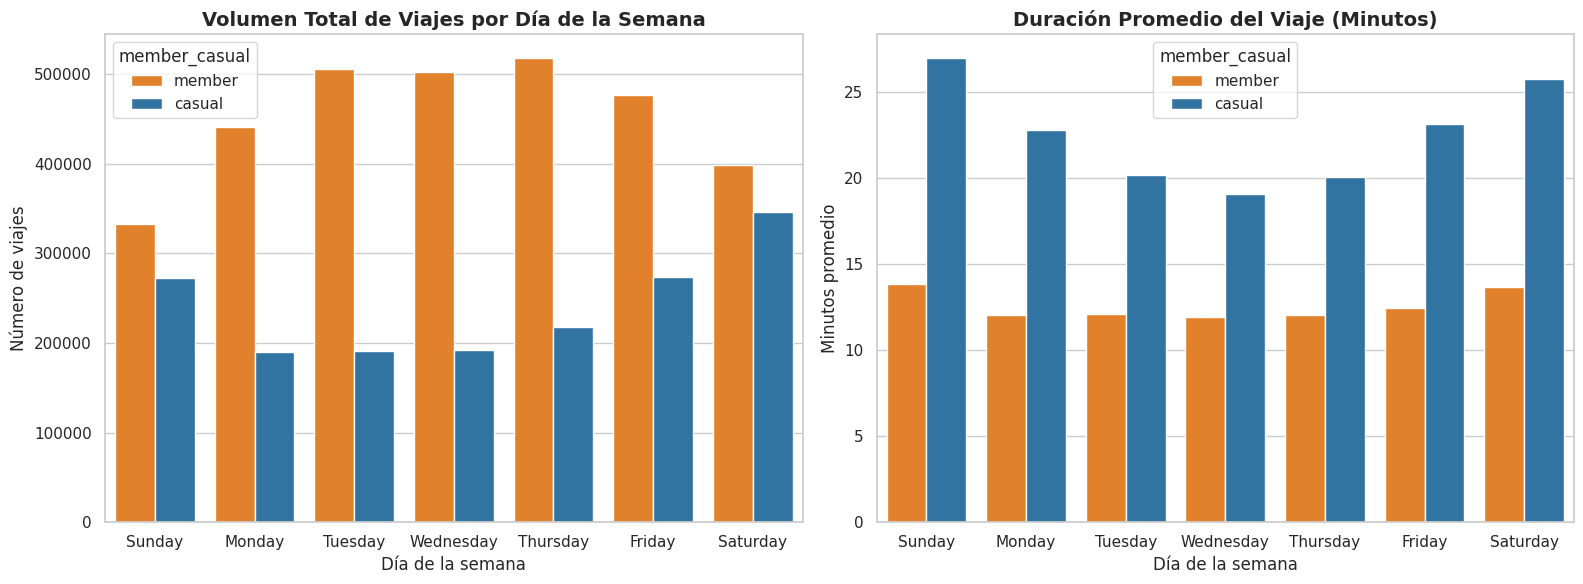

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Gráfico de volumen de viajes por día de la semana
sns.countplot(
    data=df_clean,
    x='day_name',
    hue='member_casual',
    order=orden_dias,
    palette=['#ff7f0e', '#1f77b4'],
    ax=axes[0]
)
axes[0].set_title('Volumen Total de Viajes por Día de la Semana', fontsize=14, weight='bold')
axes[0].set_xlabel('Día de la semana')
axes[0].set_ylabel('Número de viajes')
axes[0].ticklabel_format(style='plain', axis='y')

# 2. Gráfico de duración promedio por día de la semana
sns.barplot(
    data=df_clean,
    x='day_name',
    y='ride_length',
    hue='member_casual',
    order=orden_dias,
    palette=['#ff7f0e', '#1f77b4'],
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Duración Promedio del Viaje (Minutos)', fontsize=14, weight='bold')
axes[1].set_xlabel('Día de la semana')
axes[1].set_ylabel('Minutos promedio')

plt.tight_layout()
plt.show()

In [ ]:
fig.savefig("cyclistic_weekly_patterns.png", dpi=300, bbox_inches='tight')
print("Imagen guardada en el panel de archivos como 'cyclistic_weekly_patterns.png'")

Imagen guardada en el panel de archivos como 'cyclistic_weekly_patterns.png'
